# P1 — Quantum-Safe Secure Communication Channel: end-to-end notebook
Runs top to bottom (*Restart & Run All*). It **does not overwrite** `results/`: the mini-benchmark is quick and kept in memory;
the full results are loaded from the committed CSVs. Full benchmark: `make bench` (~6 min).

In [1]:
import os, sys, platform
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
import pandas as pd
from IPython.display import Image, display, Markdown
from src.kem import BACKEND_VERSION
from src.sig import SIG_BACKEND_VERSION
print("Python", platform.python_version()); print(BACKEND_VERSION); print(SIG_BACKEND_VERSION)

Python 3.12.3
cryptography 50.0.2; kyber-py 1.2.0
cryptography 50.0.2; dilithium-py 1.5.1


## 1. The channel: handshake and application data for all three suites

In [2]:
import hashlib, random
from src.channel import Client, Server, make_identities, run_handshake
from src.problem import SUITES, SUITE_SIG
ids = make_identities()          # long-term ML-DSA-65 and ECDSA-P256 server keys (pinned by the client)
data = random.Random(42).randbytes(100_000)
rows = []
for s in SUITES:
    r = run_handshake(Client(s, ids[SUITE_SIG[s]][0]), Server(ids))
    got = r.server.recv(r.client.send(data))
    rows.append({"suite": s, "handshake bytes c2s": r.counter.c2s, "s2c": r.counter.s2c,
                 "client compute ms": r.client_ns / 1e6, "server compute ms": r.server_ns / 1e6,
                 "100 KB payload intact": hashlib.sha256(got).digest() == hashlib.sha256(data).digest(),
                 "send_key != recv_key": r.client.send_key != r.client.recv_key})
pd.DataFrame(rows).round(2)

,suite,handshake bytes c2s,s2c,client compute ms,server compute ms,100 KB payload intact,send_key != recv_key
0,P256,150,214,0.77,10.63,True,True
1,MLKEM768,1271,4484,17.63,73.98,True,True
2,P256+MLKEM768,1341,4554,18.19,63.90,True,True


## 2. Attacks (each asserted in `tests/test_attacks.py`)
`attack_succeeded` should be **False** everywhere except the unauthenticated negative control.

In [3]:
from src import attacks as A
from src.problem import SUITE_HYBRID
res = [A.passive_eavesdropper(SUITE_HYBRID, ids), A.mitm_fake_server(SUITE_HYBRID, ids, make_identities()),
       A.mitm_substitute_kem(SUITE_HYBRID, ids), A.downgrade(ids, SUITE_HYBRID), *A.record_attacks("P256", ids),
       A.mitm_unsigned_control(SUITE_HYBRID)]
tam = A.tamper_all(SUITE_HYBRID, ids)
out = pd.DataFrame([{"attack": r.name, "attack_succeeded": r.attack_succeeded, "detail": r.detail} for r in res])
display(out)
print(f"single-bit handshake tampers tried: {len(tam)}, succeeded: {sum(r.attack_succeeded for r in tam)}")
assert not any(r.attack_succeeded for r in res[:-1]) and res[-1].attack_succeeded and not any(r.attack_succeeded for r in tam)

,attack,attack_succeeded,detail
0,passive_eavesdropper,False,observed 6035 bytes on wire
1,mitm_fake_server_signed,False,server signature invalid
2,mitm_substitute_kem_signed,False,server signature invalid
3,downgrade,False,suite mismatch (downgrade?)
4,record_tamper,False,record authentication failed
5,record_drop,False,bad sequence number (replay/reorder/drop)
6,record_reorder,False,bad sequence number (replay/reorder/drop)
7,record_replay,False,bad sequence number (replay/reorder/drop)
8,mitm_unsigned_control,True,attacker read + relayed plaintext


single-bit handshake tampers tried: 39, succeeded: 0


## 3. Mini benchmark on Platform A and B (quick mode, in memory only)
Tiny iteration counts: numbers here are illustrative and noisy. The real data is in section 4.

In [4]:
from src.routing import run_isolated
rows = []
for p in ("A", "B"):
    res = run_isolated(f"processors/processor_{p}.json", "scripts/run_benchmark.py", ["--mode", "latency", "--quick"])
    rows += res["rows"]
q = pd.DataFrame(rows)
q = q[(q.pass_type == "latency") & (q.operation == "handshake_total")]
q[["platform", "suite", "median_us", "bytes_c2s", "bytes_s2c", "cpu_affinity_effective", "rlimit_as_mb_effective"]].round(0)

,platform,suite,median_us,bytes_c2s,bytes_s2c,cpu_affinity_effective,rlimit_as_mb_effective
13,platform_A,P256,664.0,150.0,214.0,0,
17,platform_A,MLKEM768,76656.0,1271.0,4484.0,0,
21,platform_A,P256+MLKEM768,47072.0,1341.0,4554.0,0,
41,platform_B,P256,680.0,150.0,214.0,0,256
45,platform_B,MLKEM768,60984.0,1271.0,4484.0,0,256
49,platform_B,P256+MLKEM768,88274.0,1341.0,4554.0,0,256


## 4. Full results (committed CSVs from `make bench`: 3 repeats x 100 iterations)

In [5]:
pd.read_csv("results/tables/final_comparison.csv")

,Metric,Platform A,Platform B,Difference,Platform B contended (extra),Difference (contended vs A)
0,"Handshake latency, hybrid (ms, median)",57.623,66.978,+9.36 (1.16x),127.235,+69.61 (2.21x)
1,"Handshake bytes c2s+s2c, hybrid (bytes)",5895.000,5895.000,+0.00 (1.00x),5895.000,+0.00 (1.00x)
2,"Ciphertext size, hybrid KEM (bytes)",1153.000,1153.000,+0.00 (1.00x),1153.000,+0.00 (1.00x)
3,"Peak memory, hybrid handshake: tracemalloc (KB)",1194.779,1194.590,-0.19 (1.00x),1194.645,-0.13 (1.00x)
4,"Peak RSS, hybrid handshake process (MB)",36.598,36.578,-0.02 (1.00x),36.500,-0.10 (1.00x)
5,"Peak RSS, 10 MB bulk process (MB)",71.516,71.305,-0.21 (1.00x),71.414,-0.10 (1.00x)
6,"Throughput, 10 MB payload (MB/s)",523.190,499.005,-24.19 (0.95x),213.722,-309.47 (0.41x)
7,"Code size, src/ (LOC, non-blank non-comment)",730.000,730.000,+0.00 (1.00x),730.000,+0.00 (1.00x)


In [6]:
ab = pd.read_csv("results/tables/AB_comparison.csv")
ab[["suite", "operation", "payload_bytes", "median_us_A", "median_us_B", "ratio_B_over_A", "ci_note"]].round(2)

,suite,operation,payload_bytes,median_us_A,median_us_B,ratio_B_over_A,ci_note
0,ECDSAP256,sign,NaN,132.79,137.28,1.03,spread_A=17.1% spread_B=13.1% ok
1,ECDSAP256,verify,NaN,190.99,201.25,1.05,spread_A=13.5% spread_B=11.8% ok
2,MLDSA65,sign,NaN,40465.98,35531.87,0.88,spread_A=8.3% spread_B=2.0% ok
3,MLDSA65,verify,NaN,8903.92,9471.97,1.06,spread_A=11.7% spread_B=55.6% HIGH run-to-run ...
4,MLKEM768,decaps,NaN,4843.44,4750.76,0.98,spread_A=9.3% spread_B=5.1% ok
5,MLKEM768,encaps,NaN,3842.73,3606.51,0.94,spread_A=15.0% spread_B=23.2% HIGH run-to-run ...
6,MLKEM768,handshake_client_compute,NaN,16427.18,17487.94,1.06,spread_A=5.9% spread_B=12.9% ok
7,MLKEM768,handshake_server_compute,NaN,43845.35,46345.05,1.06,spread_A=2.5% spread_B=22.9% HIGH run-to-run s...
8,MLKEM768,handshake_total,NaN,61990.03,64492.64,1.04,spread_A=1.7% spread_B=16.7% ok
9,MLKEM768,keygen,NaN,2674.52,2676.68,1.00,spread_A=39.5% spread_B=4.3% HIGH run-to-run s...


## 5. Figures (regenerated from the CSVs)

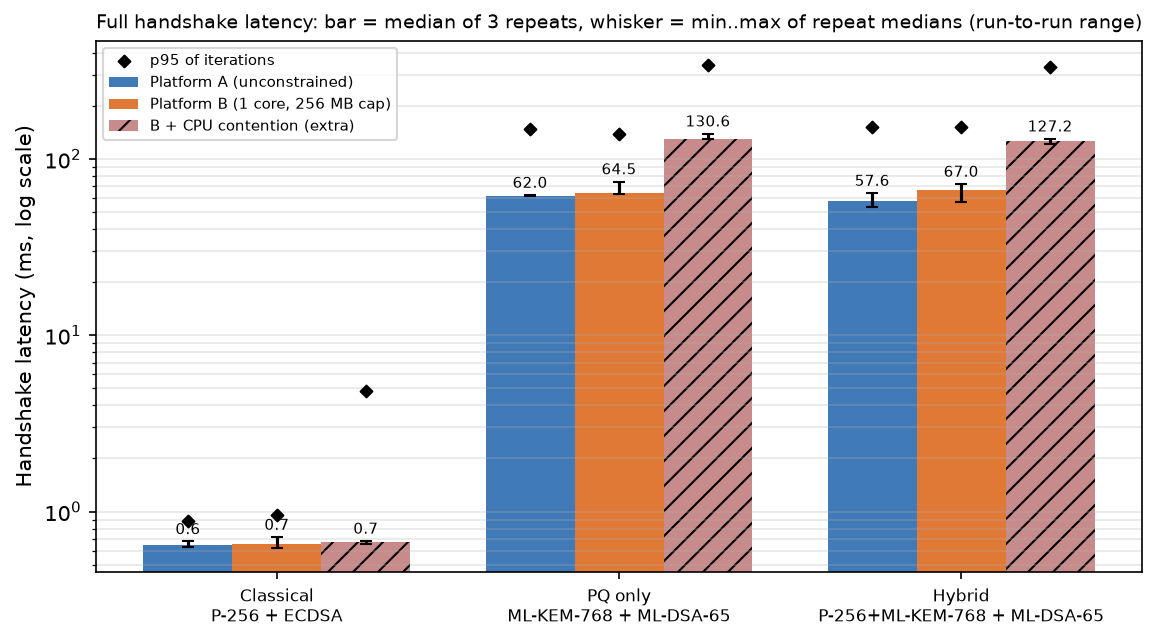

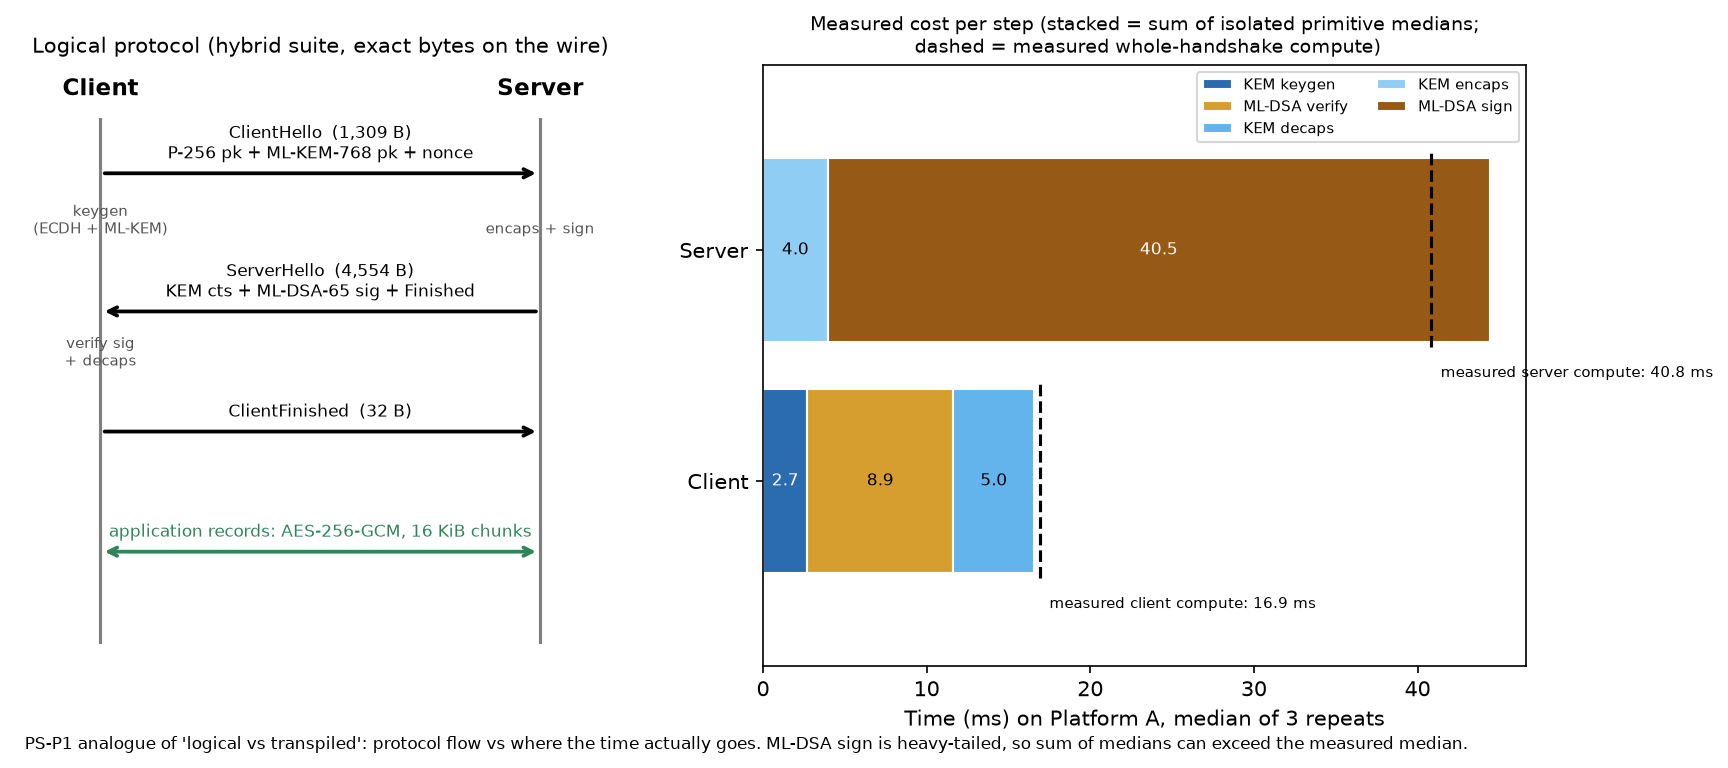

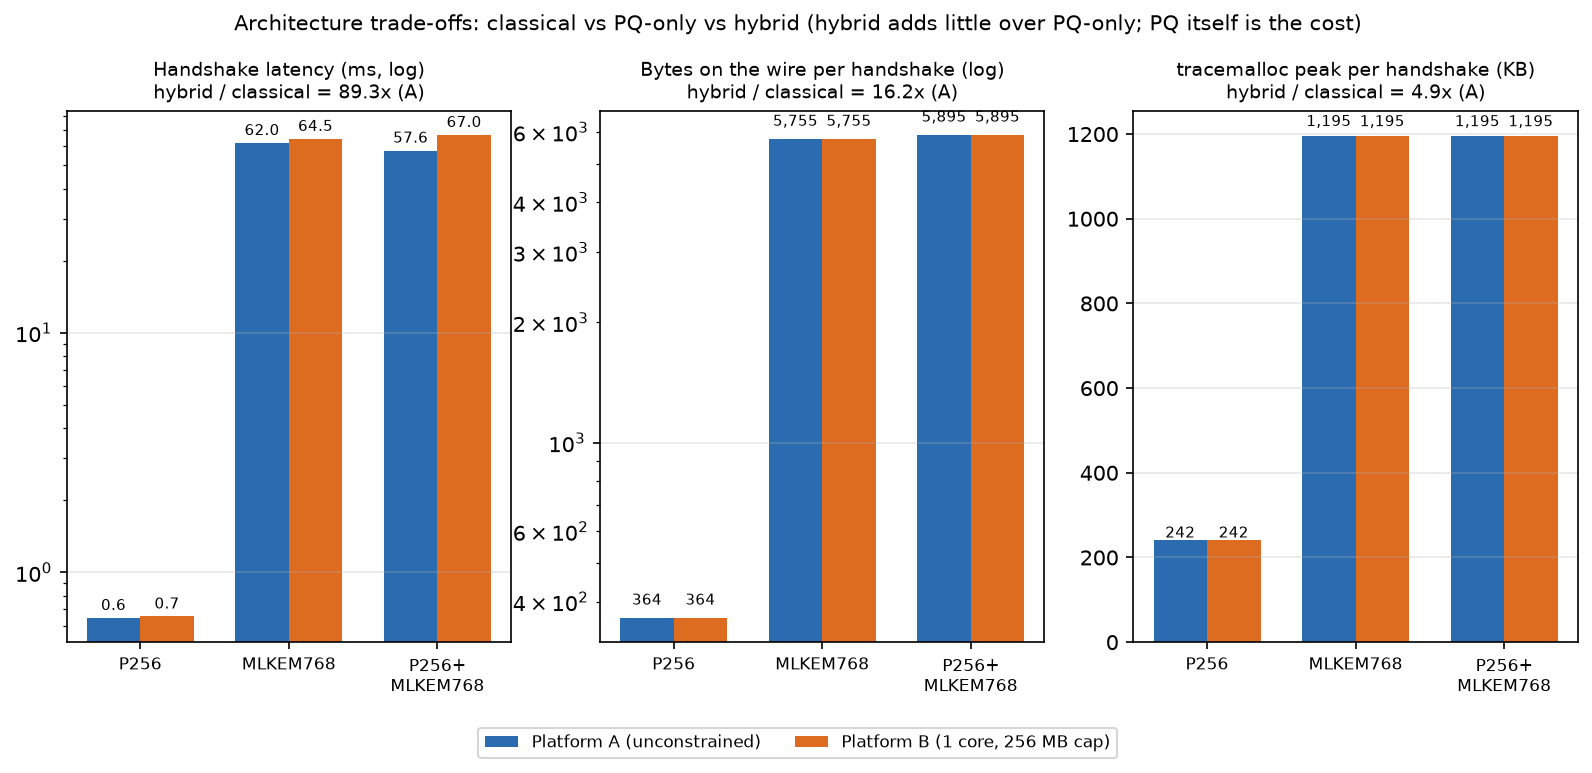

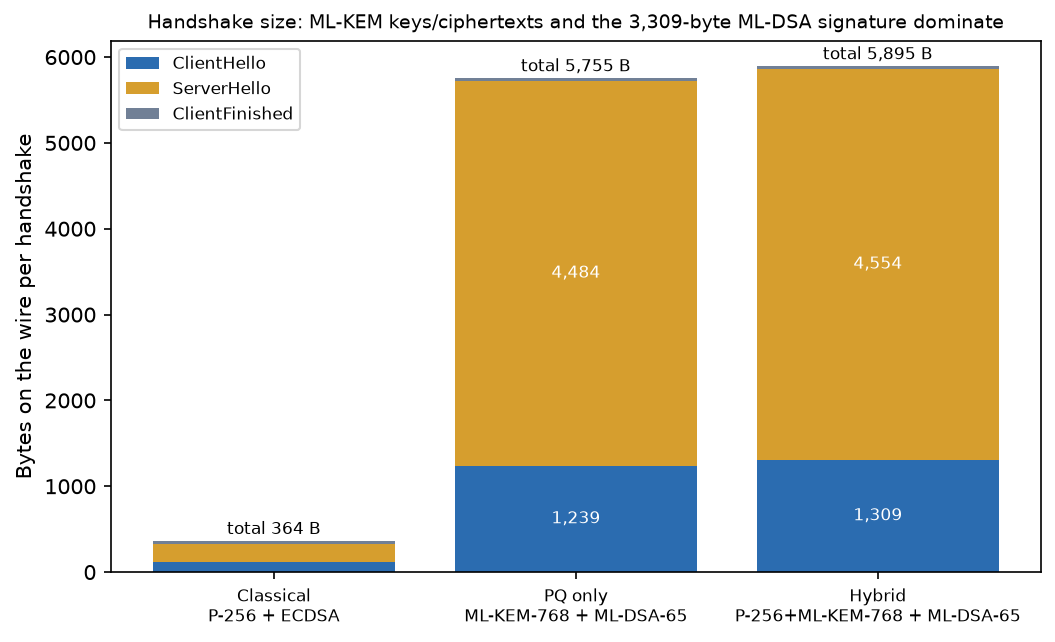

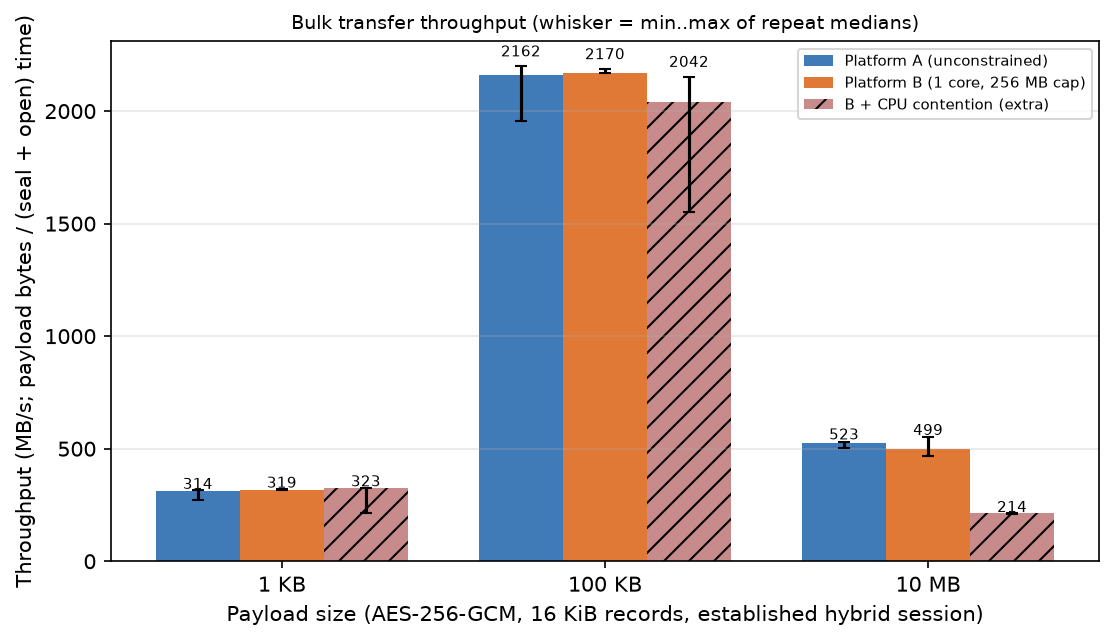

In [7]:
from src.visualization import make_all
make_all()
for f in ["AB_performance", "logical_vs_transpiled", "architecture_tradeoffs", "bytes_on_wire", "throughput_payloads"]:
    display(Image(f"results/figures/{f}.png"))

## 6. Self-checks

In [8]:
import subprocess
for cmd in (["scripts/spot_check_report.py"], ["scripts/check_repo.py", "--results-only"]):
    r = subprocess.run([sys.executable, *cmd], capture_output=True, text=True)
    print(cmd[0], "->", "OK" if r.returncode == 0 else "FAILED"); print(r.stdout.strip().splitlines()[-1])

scripts/spot_check_report.py -> OK
0 mismatches


scripts/check_repo.py -> OK
36/36 checks passed
